# 1. Build Features from Raw Keystroke Logs

This notebook turns raw keydown/keyup event logs (`.jsonl`, one JSON object per line, one file per capture session)
into a table of numeric features — one row per sliding window of keystrokes — that a model can actually learn from.

**Pipeline for each session file:**
1. **Load** the raw events.
2. **Clean** — drop exact duplicate events and minority-device artifacts (some BT keyboards report on two HID interfaces at once).
3. **Pair** keydown/keyup events into `dwell_ms` (how long a key was held) and `flight_ms` (gap since the previous key was released).
4. **Window** — slide a window of 25 keystrokes (5 at a time) over the paired events and compute aggregate stats per window: mean/std/CV of dwell and flight times, events per second, backspace ratio, etc.
5. Concatenate every session's windows into one `features.csv`.

Run this first. It reads from `../data/raw` and produces `../data/processed/features.csv`
(the top-level `data/` folder is the single source of truth — there is no separate `ml/data/` copy anymore).


## Config

Edit `RAW_DIR` to point at the folder containing your `.jsonl` capture files.

In [1]:
import os

RAW_DIR = "../data/raw"           # folder of raw .jsonl session files (single source of truth)
OUT_DIR = "../data/processed"     # where features.csv gets written
WINDOW_SIZE = 25                  # keystrokes per sliding window (canonical configuration)
WINDOW = WINDOW_SIZE              # alias for compatibility
STEP = 5                          # stride between windows (smaller = more overlap)

os.makedirs(OUT_DIR, exist_ok=True)


## Imports

In [2]:
import glob
import json

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

%matplotlib inline


## Constants

Bit flags and thresholds used while pairing/cleaning events. These come straight from the
Windows Raw Input `RAWKEYBOARD.Flags` field and standard keystroke-dynamics practice.

In [3]:
# RI_KEY_BREAK bit — set on any keyup event (plain or extended/E0)
FLAG_BREAK_BIT = 0x01
# RI_KEY_E0 bit — marks "extended" keys (many keys reuse scan codes between
# the base and E0-prefixed variants, e.g. main Enter vs numpad Enter)
FLAG_E0_BIT = 0x02

VK_BACK = 0x08
VK_DELETE = 0x2E

# Flight-time gaps longer than this are treated as "thinking pauses" (or, in
# injected sessions, the delay before typing starts) rather than typing
# rhythm — standard practice in keystroke dynamics literature. Excluded from
# mean/std/CV but counted separately per window.
PAUSE_THRESHOLD_MS = 2000

# Dwell times longer than this are a deliberate long hold (or a stuck/
# unmatched key) rather than typing rhythm — same logic as above.
DWELL_CAP_MS = 2000


## Step 1 — Load raw sessions

Reads every `.jsonl` file in `RAW_DIR` into one long DataFrame, tagging each row with its
source filename so sessions never get mixed together.

In [4]:
def load_sessions(raw_dir: str) -> pd.DataFrame:
    files = sorted(glob.glob(os.path.join(raw_dir, "*.jsonl")))
    if not files:
        raise SystemExit(f"No .jsonl files found in {raw_dir}")

    frames = []
    for f in files:
        rows = []
        with open(f, encoding="utf-8") as fh:
            for line in fh:
                line = line.strip()
                if not line:
                    continue
                rows.append(json.loads(line))
        if not rows:
            continue
        df = pd.DataFrame(rows)
        df["source_file"] = os.path.basename(f)
        frames.append(df)

    full = pd.concat(frames, ignore_index=True, sort=False)

    # Backfill optional columns so downstream code can assume they exist
    for col, default in [
        ("seq", np.nan),
        ("qpc_ticks", np.nan),
        ("device_handle", ""),
        ("message", np.nan),
        ("is_autorepeat", np.nan),
        ("payload_variant", None),
    ]:
        if col not in full.columns:
            full[col] = default

    return full

raw = load_sessions(RAW_DIR)
print(f"Loaded {len(raw)} events across {raw['source_file'].nunique()} files")
raw.head()


Loaded 136276 events across 150 files


,device_handle,device_path,flags,is_autorepeat,label,message,payload_variant,qpc_ticks,scan_code,seq,session_id,subject_id,timestamp_ns,vkey,source_file,dev221ice_path
0,0x200b9,\\?\HID#{00001812-0000-1000-8000-00805f9b34fb}...,0,False,human,256,None,228741850435,32,1,adhi_01.,s05,1786549389378158800,68,adhi_01.jsonl,NaN
1,0x200b9,\\?\HID#{00001812-0000-1000-8000-00805f9b34fb}...,1,False,human,257,None,228743228745,32,2,adhi_01.,s05,1786549389515989900,68,adhi_01.jsonl,NaN
2,0x200b9,\\?\HID#{00001812-0000-1000-8000-00805f9b34fb}...,0,False,human,256,None,228743679785,24,3,adhi_01.,s05,1786549389561093700,79,adhi_01.jsonl,NaN
3,0x200b9,\\?\HID#{00001812-0000-1000-8000-00805f9b34fb}...,1,False,human,257,None,228744588730,24,4,adhi_01.,s05,1786549389651988300,79,adhi_01.jsonl,NaN
4,0x200b9,\\?\HID#{00001812-0000-1000-8000-00805f9b34fb}...,0,False,human,256,None,228752410505,17,5,adhi_01.,s05,1786549390434165800,87,adhi_01.jsonl,NaN


## Step 2 — Clean each session

Two artifacts show up in real captures and need removing before pairing:
1. **Exact duplicate events** — a device double-reporting the same HID input report.
2. **Minority device_path(s)** — some BT keyboards expose two HID interfaces for the same
   physical device, so a session can end up with a small fraction of events on a second
   device handle. Mixing two interfaces' timestamps corrupts the flight-time math, so we
   keep only the dominant `device_path` per session.

In [5]:
def clean_session(session: pd.DataFrame, log_prefix: str) -> pd.DataFrame:
    before = len(session)

    dedup_cols = [c for c in ["timestamp_ns", "vkey", "scan_code", "flags"]
                  if c in session.columns]
    session = session.drop_duplicates(subset=dedup_cols).reset_index(drop=True)
    n_dupes = before - len(session)

    n_minority_dropped = 0
    if "device_path" in session.columns and session["device_path"].nunique() > 1:
        counts = session["device_path"].value_counts()
        dominant = counts.idxmax()
        minority_mask = session["device_path"] != dominant
        n_minority_dropped = int(minority_mask.sum())
        session = session[~minority_mask].reset_index(drop=True)

    if n_dupes or n_minority_dropped:
        print(f"  [clean] {log_prefix}: dropped {n_dupes} duplicate events, "
              f"{n_minority_dropped} minority-device events")

    return session


## Step 3 — Pair keydown/keyup into dwell & flight times

- `dwell_ms` = keyup timestamp − keydown timestamp for the *same key* (matched on scan_code + E0 bit)
- `flight_ms` = this keydown's timestamp − the *previous* keyup's timestamp (gap since any key was last released)

This is the standard pairing used in keystroke-dynamics research.

In [6]:
def pair_dwell_flight(session: pd.DataFrame) -> pd.DataFrame:
    session = session.sort_values("timestamp_ns").reset_index(drop=True)

    open_keys = {}       # (scan_code, is_extended) -> keydown row info
    last_keyup_ts = None
    records = []

    for idx, row in session.iterrows():
        is_keyup = bool(int(row["flags"]) & FLAG_BREAK_BIT)
        is_extended = bool(int(row["flags"]) & FLAG_E0_BIT)
        key_id = (row["scan_code"], is_extended)

        if not is_keyup:
            flight_ms = (
                (row["timestamp_ns"] - last_keyup_ts) / 1e6
                if last_keyup_ts is not None
                else np.nan
            )
            open_keys[key_id] = {
                "keydown_ts": row["timestamp_ns"],
                "vkey": row["vkey"],
                "scan_code": row["scan_code"],
                "flight_ms": flight_ms,
                "is_autorepeat": row.get("is_autorepeat", np.nan),
                "device_path": row.get("device_path", None),
                "seq": row.get("seq", idx),
            }
        else:
            opened = open_keys.pop(key_id, None)
            last_keyup_ts = row["timestamp_ns"]
            if opened is not None:
                dwell_ms = (row["timestamp_ns"] - opened["keydown_ts"]) / 1e6
                records.append({
                    "seq": opened["seq"],
                    "timestamp_ns": opened["keydown_ts"],
                    "vkey": opened["vkey"],
                    "scan_code": opened["scan_code"],
                    "dwell_ms": dwell_ms,
                    "flight_ms": opened["flight_ms"],
                    "is_autorepeat": opened["is_autorepeat"],
                    "device_path": opened["device_path"],
                })
            # Unmatched keyups (no prior open keydown) are silently dropped.

    return pd.DataFrame.from_records(records)


## Step 4 — Slide a window over each session and aggregate

Each window of 25 consecutive paired keystrokes becomes one row of features: how consistent
the dwell/flight times are, typing speed, backspace usage, autorepeat ratio, etc.

In [7]:
def cv(x: pd.Series) -> float:
    """Coefficient of variation: std / mean. NaN-safe, guards div-by-zero."""
    m = x.mean()
    if not np.isfinite(m) or m == 0:
        return np.nan
    return x.std() / m


def windowize(paired: pd.DataFrame, window: int, step: int, meta: dict) -> pd.DataFrame:
    n = len(paired)
    if n < window:
        return pd.DataFrame()  # session too short for even one window

    rows = []
    for start in range(0, n - window + 1, step):
        w = paired.iloc[start:start + window]

        dwell_all = w["dwell_ms"].dropna()
        dwell_outlier_mask = dwell_all > DWELL_CAP_MS
        n_dwell_outliers = int(dwell_outlier_mask.sum())
        dwell = dwell_all[~dwell_outlier_mask]

        flight_all = w["flight_ms"].dropna()
        pause_mask = flight_all > PAUSE_THRESHOLD_MS
        n_pauses = int(pause_mask.sum())
        flight = flight_all[~pause_mask]

        span_s = (w["timestamp_ns"].iloc[-1] - w["timestamp_ns"].iloc[0]) / 1e9
        events_per_sec = (len(w) / span_s) if span_s > 0 else np.nan

        backspace_ratio = w["vkey"].isin([VK_BACK, VK_DELETE]).mean()

        if w["is_autorepeat"].notna().any():
            autorepeat_ratio = w["is_autorepeat"].astype(float).mean()
        else:
            autorepeat_ratio = np.nan

        n_devices = w["device_path"].nunique(dropna=True)

        rows.append({
            **meta,
            "window_start_seq": w["seq"].iloc[0],
            "mean_dwell_ms": dwell.mean(),
            "std_dwell_ms": dwell.std(),
            "cv_dwell": cv(dwell),
            "n_dwell_outliers_excluded": n_dwell_outliers,
            "mean_flight_ms": flight.mean(),
            "std_flight_ms": flight.std(),
            "cv_flight": cv(flight),
            "n_pauses_excluded": n_pauses,
            "autorepeat_ratio": autorepeat_ratio,
            "backspace_ratio": backspace_ratio,
            "events_per_sec": events_per_sec,
            "n_devices_in_window": n_devices,
        })

    return pd.DataFrame(rows)


## Step 5 — Run the pipeline over every session

In [8]:
all_windows = []
for source_file, session in raw.groupby("source_file"):
    session = clean_session(session, source_file)
    paired = pair_dwell_flight(session)
    if paired.empty:
        print(f"  [skip] {source_file}: no complete keydown/keyup pairs")
        continue

    meta = {
        "source_file": source_file,
        "label": session["label"].iloc[0],
        "subject_id": session["subject_id"].iloc[0],
        "session_id": session["session_id"].iloc[0],
        "payload_variant": session["payload_variant"].iloc[0],
    }
    windows = windowize(paired, WINDOW, STEP, meta)
    if windows.empty:
        print(f"  [skip] {source_file}: fewer than {WINDOW} paired keystrokes")
        continue

    all_windows.append(windows)

features = pd.concat(all_windows, ignore_index=True)
print(f"\nWrote {len(features)} feature rows across {features['session_id'].nunique()} sessions")
features.head()



Wrote 13046 feature rows across 150 sessions


,source_file,label,subject_id,session_id,payload_variant,window_start_seq,mean_dwell_ms,std_dwell_ms,cv_dwell,n_dwell_outliers_excluded,mean_flight_ms,std_flight_ms,cv_flight,n_pauses_excluded,autorepeat_ratio,backspace_ratio,events_per_sec,n_devices_in_window
0,adhi_01.jsonl,human,s05,adhi_01.,None,1,109.971985,23.494044,0.213637,0,201.515584,180.326140,0.894850,0,0.0,0.0,3.368770,1
1,adhi_01.jsonl,human,s05,adhi_01.,None,11,111.532505,24.103884,0.216115,0,199.014470,190.992680,0.959692,0,0.0,0.0,3.524026,1
2,adhi_01.jsonl,human,s05,adhi_01.,None,21,111.477850,24.057649,0.215807,0,175.303155,191.584534,1.092876,0,0.0,0.0,3.694730,1
3,adhi_01.jsonl,human,s05,adhi_01.,None,31,113.166520,24.909279,0.220112,0,147.881905,191.194618,1.292887,0,0.0,0.0,3.982943,1
4,adhi_01.jsonl,human,s05,adhi_01.,None,41,119.366870,25.537300,0.213940,0,136.567280,190.461085,1.394632,0,0.0,0.0,4.105582,1


## Step 6 — Save `features.csv`

In [9]:
features_path = os.path.join(OUT_DIR, "features.csv")
features.to_csv(features_path, index=False)
print(f"Saved -> {features_path}")

print("\nLabel counts:")
print(features["label"].value_counts())


Saved -> ../data/processed\features.csv

Label counts:
label
injected    8150
human       4896
Name: count, dtype: int64


## Step 7 — Quick EDA: do human vs. injected actually look different?

For each candidate feature, plot the human vs. injected distributions and run a
Mann-Whitney U test (non-parametric, doesn't assume normal distributions) to check whether
the two classes are statistically separable on that feature alone.

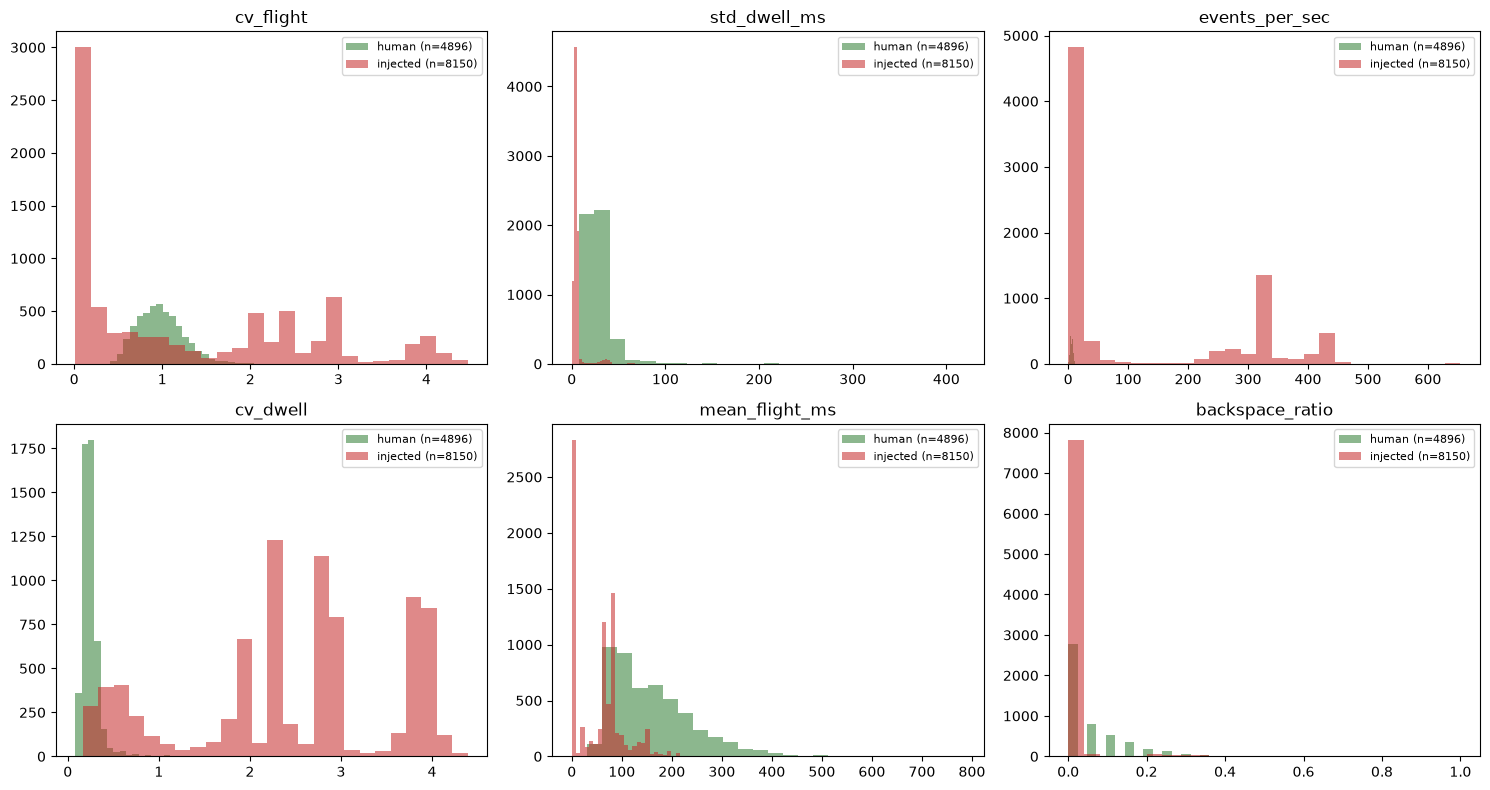

,feature,human_median,injected_median,mannwhitney_p,separates_well (p<0.05)
0,cv_flight,0.962338,0.686421,4.729067e-21,True
1,std_dwell_ms,25.430548,4.576025,0.000000e+00,True
2,events_per_sec,5.373185,16.177766,0.000000e+00,True
3,cv_dwell,0.232530,2.592987,0.000000e+00,True
4,mean_flight_ms,143.107230,63.930983,0.000000e+00,True
5,backspace_ratio,0.000000,0.000000,0.000000e+00,True


In [10]:
EDA_FEATURES = ["cv_flight", "std_dwell_ms", "events_per_sec",
                 "cv_dwell", "mean_flight_ms", "backspace_ratio"]

human = features[features["label"] == "human"]
injected = features[features["label"] == "injected"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()
results = []

for i, feat in enumerate(EDA_FEATURES):
    h = human[feat].dropna()
    inj = injected[feat].dropna()

    ax = axes[i]
    if len(h) > 0:
        ax.hist(h, bins=25, alpha=0.55, label=f"human (n={len(h)})", color="#2e7d32")
    if len(inj) > 0:
        ax.hist(inj, bins=25, alpha=0.55, label=f"injected (n={len(inj)})", color="#c62828")
    ax.set_title(feat)
    ax.legend(fontsize=8)

    if len(h) > 1 and len(inj) > 1:
        stat, p = stats.mannwhitneyu(h, inj, alternative="two-sided")
    else:
        stat, p = np.nan, np.nan

    results.append({
        "feature": feat, "human_median": h.median(), "injected_median": inj.median(),
        "mannwhitney_p": p, "separates_well (p<0.05)": (p < 0.05) if pd.notna(p) else None,
    })

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "eda_distributions.png"), dpi=130)
plt.show()

pd.DataFrame(results)


---
**Next:** open `02_train_model.ipynb` to train the Random Forest on `features.csv`.